In [1]:
# Get all libraries and functions required
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shapely
from shapely.geometry import Point, LineString
from shapely.geometry import Polygon
from scipy.interpolate import griddata
from scipy.interpolate import RegularGridInterpolator
from matplotlib.path import Path
from matplotlib.lines import Line2D
from matplotlib.gridspec import GridSpec

In [2]:
## Ground survey data processing
# Load and prepare ground survey data

csv_file = "GroundSurveyData_G1.csv"

df = pd.read_csv(csv_file)

# Rename columns
df = df.rename(columns={
    "Point ID": "point_id",
    "Northing-X": "northing",
    "Easting-Y": "easting",
    "Elevation (MSL)": "elevation",
    "Code": "code"
})

# Remove extra spaces from the Code field
df["code"] = df["code"].astype(str).str.strip().str.lower()

# Convert coordinate and elevation fields to numeric
for column in ["easting", "northing", "elevation"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Remove rows with invalid coordinates or elevations
df = df.dropna(subset=["easting", "northing", "elevation"])

print(df.head())
print(df["code"].value_counts())

  point_id    northing    easting  elevation code
0      001 -296476.037  13704.740      5.684   p1
1      002 -296476.722  13703.947      5.590   p1
2      003 -296477.409  13703.191      5.503   p1
3      004 -296478.038  13702.401      5.449   p1
4      005 -296478.669  13701.618      5.379   p1
code
grid    173
p1       92
p3       72
p5       72
p2       71
p6       71
p4       68
Name: count, dtype: int64


In [3]:
# Define the Area of Interest and clean data outside of it
csv_path = "AOI.csv"

dfv = pd.read_csv(csv_path)

# Keep only rows with valid X and Y values
dfv = dfv.dropna(subset=["X", "Y"])

# Convert coordinates to numeric values
dfv["X"] = pd.to_numeric(dfv["X"])
dfv["Y"] = pd.to_numeric(dfv["Y"])

# Create coordinate pairs
polygon_coordinates = list(zip(dfv["X"], dfv["Y"]))

# Close the polygon if the final point is not equal to the first
if polygon_coordinates[0] != polygon_coordinates[-1]:
    polygon_coordinates.append(polygon_coordinates[0])

# Create the polygon
area_polygon = Polygon(polygon_coordinates)

# Remove points outside of the polygon area
df["inside_area"] = df.apply(
    lambda row: area_polygon.covers(
        Point(row["easting"], row["northing"])
    ),
    axis=1
)

df_clean = df[df["inside_area"]].copy()

print(f"Original points: {len(df)}")
print(f"Points inside area: {len(df_clean)}")
print(f"Removed points: {len(df) - len(df_clean)}")

Original points: 619
Points inside area: 577
Removed points: 42


In [4]:
# Define profile survey codes and classify the points by profile or grid
profile_codes = ["p1", "p2", "p3", "p4", "p5", "p6"]

profiles_clean = df_clean[
    df_clean["code"].isin(profile_codes)
].copy()

grid_clean = df_clean[
    df_clean["code"] == "grid"
].copy()

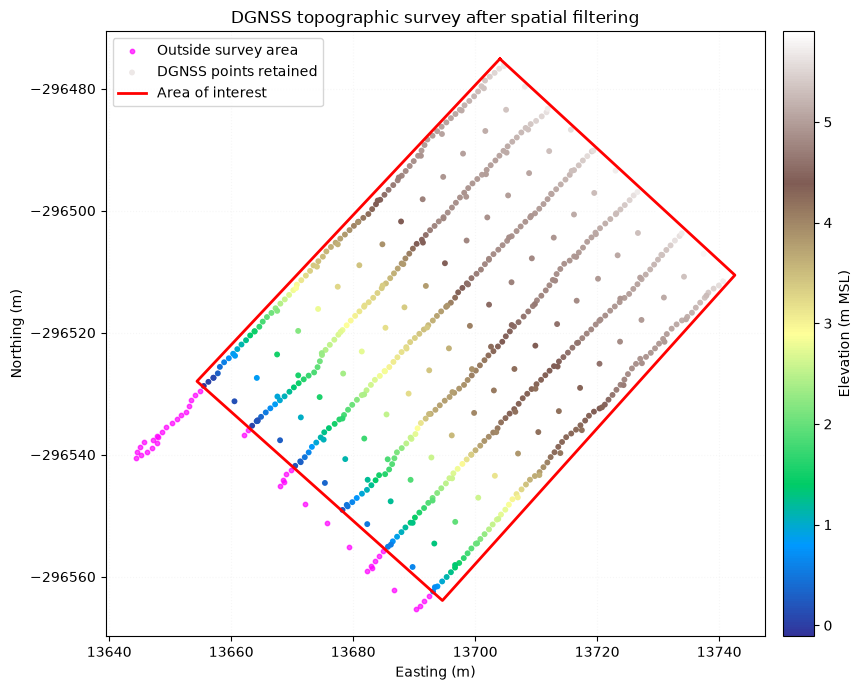

In [5]:
# Plot the cleaned data for visual inspection
fig, ax = plt.subplots(figsize=(10, 7))

# Points rejected by the polygon filter
df_outside = df.loc[~df["inside_area"]]

ax.scatter(
    df_outside["easting"],
    df_outside["northing"],
    color="magenta",
    s=10,
    alpha=0.7,
    label="Outside survey area",
    zorder=1
)

# Retained observations, coloured by elevation
sc = ax.scatter(
    df_clean["easting"],
    df_clean["northing"],
    c=df_clean["elevation"],
    cmap="terrain",
    s=18,
    edgecolors="none",
    label="DGNSS points retained",
    zorder=2
)

# Survey-area boundary
polygon_x, polygon_y = area_polygon.exterior.xy
ax.plot(
    polygon_x,
    polygon_y,
    color="red",
    linewidth=2,
    label="Area of interest",
    zorder=3
)

cbar = fig.colorbar(sc, ax=ax, pad=0.02)
cbar.set_label("Elevation (m MSL)")

ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_title("DGNSS topographic survey after spatial filtering")
ax.set_aspect("equal", adjustable="box")
ax.legend(loc="best")
ax.grid(True, linestyle=":", alpha=0.1)

plt.tight_layout()
plt.show()

In [6]:
## Interpolation
# Define DEMs interpolation size and create grid
resolution = 5  # metres

xmin, ymin, xmax, ymax = area_polygon.bounds

x_grid = np.arange(xmin, xmax + resolution, resolution)
y_grid = np.arange(ymin, ymax + resolution, resolution)

X, Y = np.meshgrid(x_grid, y_grid)

# Mask grid cells outside the polygon
polygon_path = Path(polygon_coordinates)

grid_points = np.column_stack((X.ravel(), Y.ravel()))
inside_mask = polygon_path.contains_points(grid_points).reshape(X.shape)

# Interpolate grid survey
grid_points_xy = grid_clean[["easting", "northing"]].to_numpy()
grid_values_z = grid_clean["elevation"].to_numpy()

dem_grid_linear = griddata(
    points=grid_points_xy,
    values=grid_values_z,
    xi=(X, Y),
    method="linear",
    fill_value=np.nan
)

# Restrict the result to the polygon
dem_grid_linear[~inside_mask] = np.nan

print(dem_grid_linear.shape)
print(X.shape)

# Interpolate profile survey
profile_points_xy = profiles_clean[["easting", "northing"]].to_numpy()
profile_values_z = profiles_clean["elevation"].to_numpy()

dem_profiles_linear = griddata(
    points=profile_points_xy,
    values=profile_values_z,
    xi=(X, Y),
    method="linear",
    fill_value=np.nan
)

dem_profiles_linear[~inside_mask] = np.nan

(19, 19)
(19, 19)


In [7]:
# Check grid and profile surveys coverage of AOI
grid_points = shapely.points(X.ravel(), Y.ravel())
inside_mask = shapely.covers(area_polygon, grid_points).reshape(X.shape)

dem_grid_linear[~inside_mask] = np.nan
dem_profiles_linear[~inside_mask] = np.nan

n_inside = inside_mask.sum()

print(f"Grid DEM coverage: {np.isfinite(dem_grid_linear).sum() / n_inside:.1%}")
print(f"Profile DEM coverage: {np.isfinite(dem_profiles_linear).sum() / n_inside:.1%}")

Grid DEM coverage: 91.6%
Profile DEM coverage: 94.8%


In [8]:
## UAV-LiDAR survey processing
# Import UAV-LiDAR data 
import rasterio
from rasterio.mask import mask
from shapely.geometry import mapping

lidar_path = "dem_UAV.tif"

with rasterio.open(lidar_path) as src:
    print("CRS:", src.crs)
    print("Bounds:", src.bounds)
    print("Native resolution (m):", src.res)
    print("NoData:", src.nodata)
    print("Metadata:", src.tags())

    # Only valid after confirming area_polygon uses src.crs
    lidar_clip, lidar_transform = mask(
        src,
        [mapping(area_polygon)],
        crop=True,
        filled=False
    )

lidar_z = lidar_clip[0]

# Correct LiDAR alignment for a Y grid that increases south -> north
from rasterio.warp import reproject
from rasterio.enums import Resampling
from rasterio.transform import from_origin

dx = float(np.median(np.diff(X[0, :])))
dy = float(np.median(np.diff(Y[:, 0])))

if not (np.isclose(dx, 5.0) and np.isclose(dy, 5.0)):
    raise ValueError(f"Expected a 5 m grid, got dx={dx}, dy={dy}")

# Rasterio row 0 is the NORTHERN-most row.
# Build the standard north-to-south target raster transform.
target_transform = from_origin(
    west=X[0, 0] - dx / 2,
    north=Y[-1, 0] + dy / 2,
    xsize=dx,
    ysize=dy
)

lidar_raster_order = np.full(X.shape, np.nan, dtype=np.float32)

with rasterio.open(lidar_path) as src:
    reproject(
        source=rasterio.band(src, 1),
        destination=lidar_raster_order,
        src_transform=src.transform,
        src_crs=src.crs,
        src_nodata=src.nodata,
        dst_transform=target_transform,
        dst_crs=src.crs,
        dst_nodata=np.nan,
        resampling=Resampling.average
    )

# Flip the raster-order LiDAR once to match convention.
lidar_5m = np.flipud(lidar_raster_order)

# Apply the exact DGNSS area mask after changing orientation
lidar_5m[~inside_mask] = np.nan

print("New valid LiDAR 5 m cells:", np.isfinite(lidar_5m).sum())

CRS: EPSG:3763
Bounds: BoundingBox(left=13426.525000000001, bottom=-296881.775, right=14039.325, top=-296176.025)
Native resolution (m): (0.05, 0.05)
NoData: -9999.0
Metadata: {'AREA_OR_POINT': 'Area'}
New valid LiDAR 5 m cells: 154


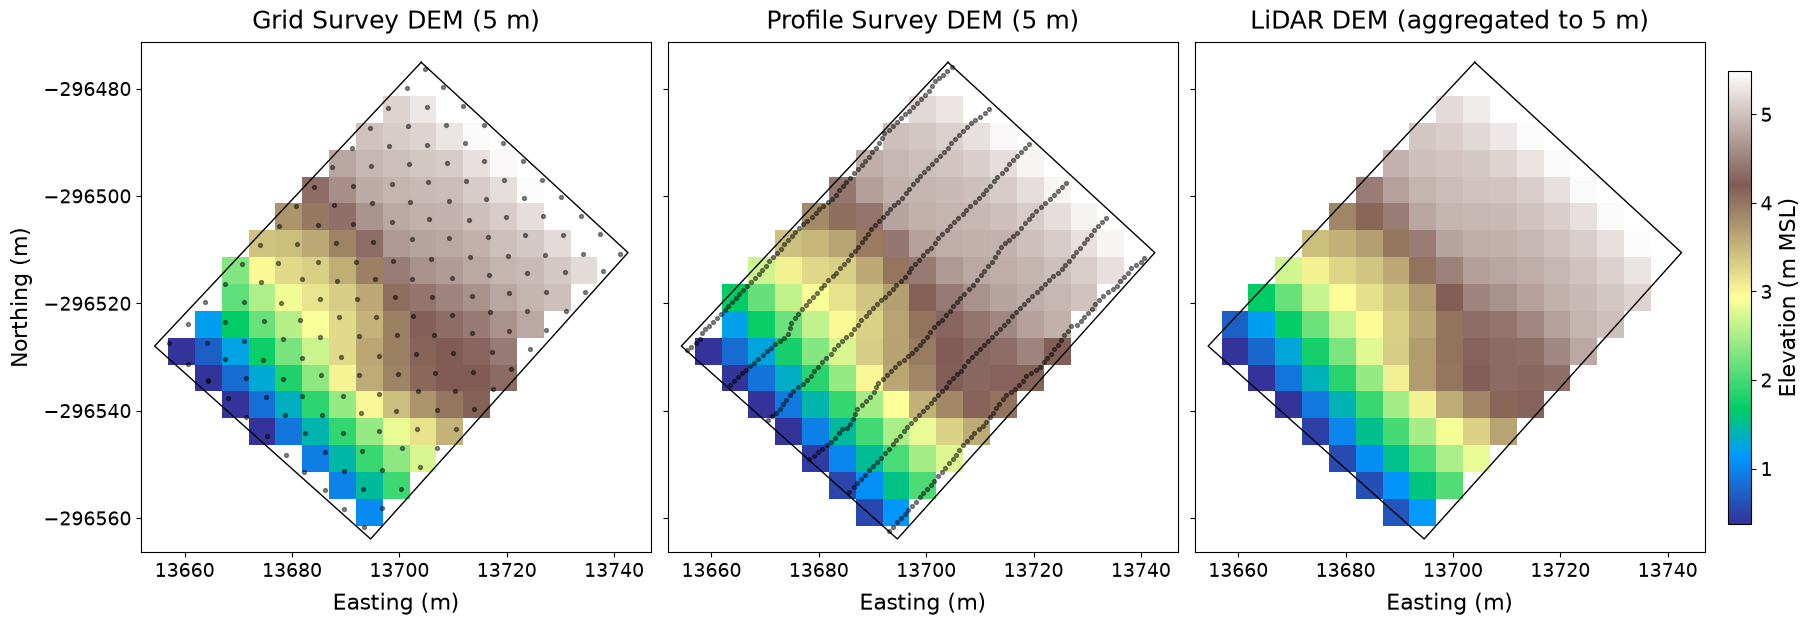

In [9]:
##  Visualize for comparison of ground surveys and UAV

valid_z = np.concatenate([
    dem_grid_linear[np.isfinite(dem_grid_linear)],
    dem_profiles_linear[np.isfinite(dem_profiles_linear)],
    lidar_5m[np.isfinite(lidar_5m)]
])

vmin, vmax = np.percentile(valid_z, [2, 98])

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 13
})

fig, axes = plt.subplots(
    1, 3, figsize=(18, 6),
    sharex=True, sharey=True, constrained_layout=True
)

products = [
    (dem_grid_linear, "Grid Survey DEM (5 m)"),
    (dem_profiles_linear, "Profile Survey DEM (5 m)"),
    (lidar_5m, "LiDAR DEM (aggregated to 5 m)")
]

polygon_x, polygon_y = area_polygon.exterior.xy

for ax, (dem, title) in zip(axes, products):
    im = ax.pcolormesh(
        X, Y, dem,
        shading="auto", cmap="terrain",
        vmin=vmin, vmax=vmax
    )
    ax.plot(polygon_x, polygon_y, color="black", linewidth=1)
    ax.set_title(title, pad=10)
    ax.set_xlabel("Easting (m)", labelpad=8)
    ax.set_aspect("equal")
    ax.tick_params(axis="both", which="major", labelsize=14)

axes[0].set_ylabel("Northing (m)", labelpad=8)

axes[0].scatter(
    grid_clean["easting"], grid_clean["northing"],
    s=8, color="black", alpha=0.45
)
axes[1].scatter(
    profiles_clean["easting"], profiles_clean["northing"],
    s=8, color="black", alpha=0.45
)

# axes[0].legend(loc="upper right", frameon=True)
# axes[1].legend(loc="upper right", frameon=True)

cbar = fig.colorbar(
    im,
    ax=axes,
    shrink=0.85,
    pad=0.015,
)
cbar.ax.tick_params(labelsize=14)
cbar.set_label("Elevation (m MSL)", fontsize=16)

fig.savefig(
    "dem_visual_comparison.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [10]:
# Build cross-shore transects from measured profile lines
# Standardized direction: low elevation -> high elevation

selected_profiles = ["p2","p3","p4","p5"]
transects = []

for profile_code in selected_profiles:

    observed = profiles_clean.loc[
        profiles_clean["code"] == profile_code,
        ["easting", "northing", "elevation"]
    ].copy()

    if len(observed) < 2:
        print(f"{profile_code.upper()} skipped: fewer than two points.")
        continue

    # Find the dominant direction of this surveyed profile.
    xy = observed[["easting", "northing"]].to_numpy()
    centre = xy.mean(axis=0)

    _, _, vh = np.linalg.svd(xy - centre, full_matrices=False)
    profile_direction = vh[0]

    # Order observations from one profile end to the other.
    chainage_raw = (xy - centre) @ profile_direction
    observed["chainage_raw"] = chainage_raw
    observed = observed.sort_values("chainage_raw").reset_index(drop=True)

    # Enforce the common sea -> dune direction:
    # the first observed point must be lower than the last.
    start_elevation = observed["elevation"].iloc[0]
    end_elevation = observed["elevation"].iloc[-1]

    if start_elevation > end_elevation:
        observed = observed.iloc[::-1].reset_index(drop=True)

    # Construct a line in the standardized low -> high direction.
    measured_line = LineString(
        observed[["easting", "northing"]].to_numpy()
    )

    # Limit to the survey area.
    transect = measured_line.intersection(area_polygon)

    if transect.geom_type == "MultiLineString":
        transect = max(transect.geoms, key=lambda geom: geom.length)

    if transect.geom_type != "LineString":
        print(f"{profile_code.upper()} skipped: no usable AOI intersection.")
        continue

    # The intersection can reverse its own coordinate order.
    # Enforce low -> high orientation again using line endpoints.
    line_start = Point(transect.coords[0])
    line_end = Point(transect.coords[-1])

    start_nearest_idx = np.argmin(
        np.hypot(
            observed["easting"].to_numpy() - line_start.x,
            observed["northing"].to_numpy() - line_start.y
        )
    )

    end_nearest_idx = np.argmin(
        np.hypot(
            observed["easting"].to_numpy() - line_end.x,
            observed["northing"].to_numpy() - line_end.y
        )
    )

    z_start = observed["elevation"].iloc[start_nearest_idx]
    z_end = observed["elevation"].iloc[end_nearest_idx]

    if z_start > z_end:
        transect = LineString(list(transect.coords)[::-1])

    transects.append({
        "code": profile_code,
        "line": transect,
        "observed": observed
    })

print("Transects used:", [item["code"].upper() for item in transects])

# Resample data for transects
# Arrays have dimensions [Y, X], so coordinate order is (northing, easting)
grid_sampler = RegularGridInterpolator(
    (y_grid, x_grid),
    dem_grid_linear,
    bounds_error=False,
    fill_value=np.nan
)

profile_sampler = RegularGridInterpolator(
    (y_grid, x_grid),
    dem_profiles_linear,
    bounds_error=False,
    fill_value=np.nan
)

lidar_sampler = RegularGridInterpolator(
    (y_grid, x_grid),
    lidar_5m,
    bounds_error=False,
    fill_value=np.nan
)

Transects used: ['P2', 'P3', 'P4', 'P5']


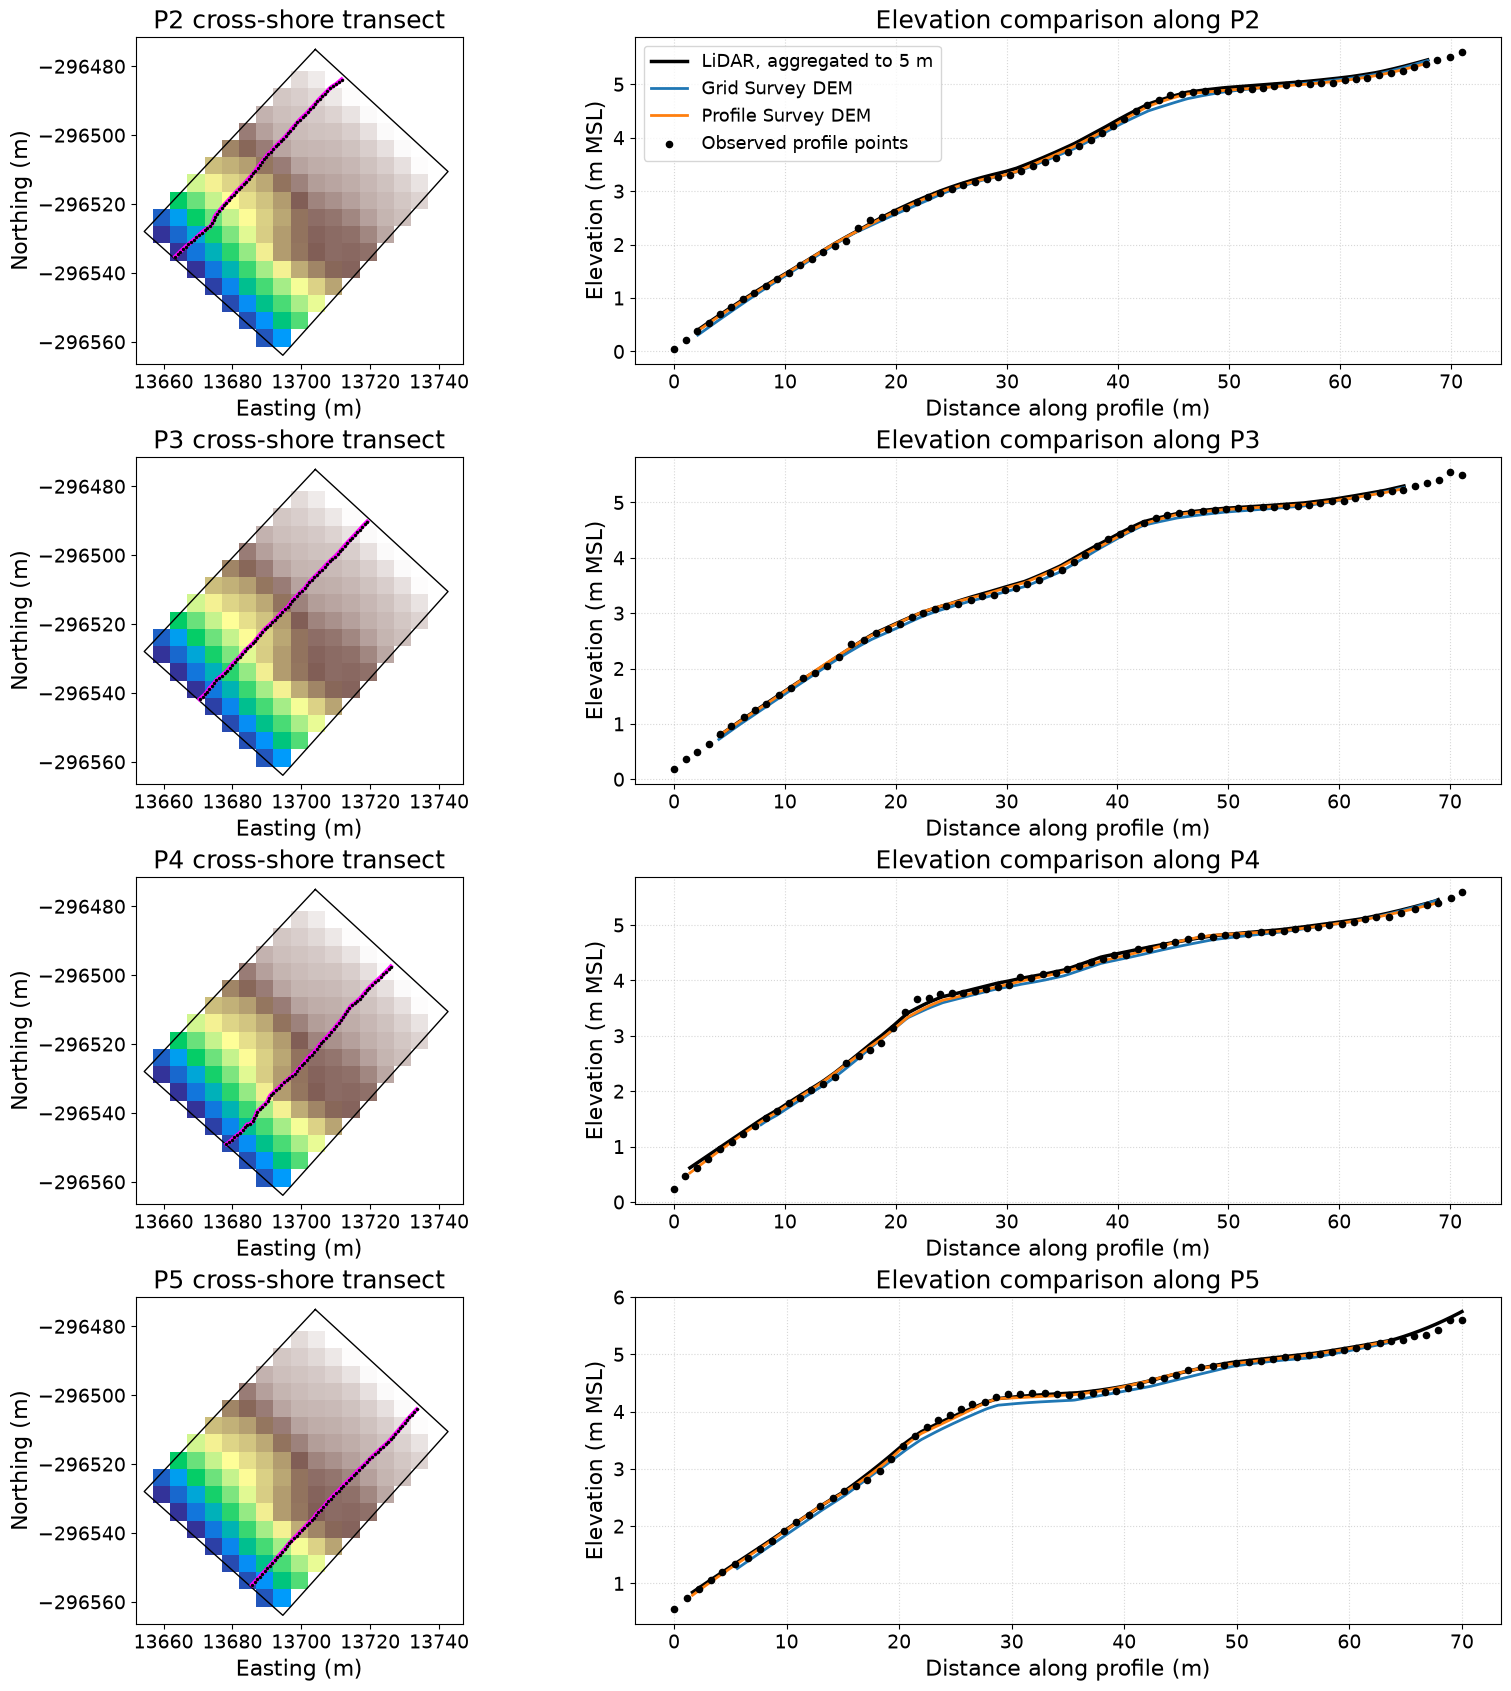

In [11]:
# Plot LiDAR, grid DEM, profile DEM, and observed DGNSS points
# along selected transects

n_samples = 300

# Shared elevation limits for all map panels
all_z = np.concatenate([
    dem_grid_linear[np.isfinite(dem_grid_linear)],
    dem_profiles_linear[np.isfinite(dem_profiles_linear)],
    lidar_5m[np.isfinite(lidar_5m)]
])

vmin, vmax = np.percentile(all_z, [2, 98])

polygon_x, polygon_y = area_polygon.exterior.xy

fig, axes = plt.subplots(
    len(transects),
    2,
    figsize=(15, 4.2 * len(transects)),
    gridspec_kw={"width_ratios": [1, 1.6]},
    constrained_layout=True,
    squeeze=False
)

for i, item in enumerate(transects):
    profile_code = item["code"]
    transect = item["line"]
    observed = item["observed"].copy()

    # Sample evenly along the actual transect geometry
    distance_m = np.linspace(0, transect.length, n_samples)
    sample_geom = [transect.interpolate(d) for d in distance_m]

    x_line = np.array([point.x for point in sample_geom])
    y_line = np.array([point.y for point in sample_geom])

    # RegularGridInterpolator uses coordinate order (Y, X)
    sample_yx = np.column_stack([y_line, x_line])

    z_grid = grid_sampler(sample_yx)
    z_profile = profile_sampler(sample_yx)
    z_lidar = lidar_sampler(sample_yx)

    # Distance of each real DGNSS point projected onto its transect
    observed["distance_m"] = observed.apply(
        lambda row: transect.project(
            Point(row["easting"], row["northing"])
        ),
        axis=1
    )
    observed = observed.sort_values("distance_m")

    # ------------------------------------------------------
    # Left panel: spatial context
    # ------------------------------------------------------
    axes[i, 0].pcolormesh(
        X, Y, lidar_5m,
        shading="auto",
        cmap="terrain",
        vmin=vmin,
        vmax=vmax
    )
    axes[i, 0].plot(
        polygon_x, polygon_y,
        color="black",
        linewidth=1
    )
    axes[i, 0].plot(
        x_line, y_line,
        color="magenta",
        linewidth=3,
        label=f"{profile_code.upper()} transect"
    )
    axes[i, 0].scatter(
        observed["easting"],
        observed["northing"],
        color="black",
        s=2,
        zorder=3,
        label="DGNSS observations"
    )

    axes[i, 0].set_title(f"{profile_code.upper()} cross-shore transect")
    axes[i, 0].set_xlabel("Easting (m)")
    axes[i, 0].set_ylabel("Northing (m)")
    axes[i, 0].set_aspect("equal")
    # axes[i, 0].legend(loc="best")

    # ------------------------------------------------------
    # Right panel: elevation comparison
    # ------------------------------------------------------
    axes[i, 1].plot(
        distance_m,
        z_lidar,
        color="black",
        linewidth=2.5,
        label="LiDAR, aggregated to 5 m"
    )
    axes[i, 1].plot(
        distance_m,
        z_grid,
        color="tab:blue",
        linewidth=2,
        label="Grid Survey DEM"
    )
    axes[i, 1].plot(
        distance_m,
        z_profile,
        color="tab:orange",
        linewidth=2,
        label="Profile Survey DEM"
    )
    axes[i, 1].scatter(
        observed["distance_m"],
        observed["elevation"],
        color="black",
        s=20,
        zorder=4,
        label="Observed profile points"
    )

    axes[i, 1].set_title(f"Elevation comparison along {profile_code.upper()}")
    axes[i, 1].set_xlabel("Distance along profile (m)")
    axes[i, 1].set_ylabel("Elevation (m MSL)")
    axes[i, 1].grid(True, linestyle=":", alpha=0.5)

axes[0, 1].legend(loc="best")

fig.savefig(
    "dem_profile_transects_comparison.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [12]:
# Build Inter-Profile Transects
# Test DEM behaviour comparing interpolated values in different zones

# Use the previously prepared transects.
# Their coordinates are low-to-high cross-shore lines.
profile_lines = [item["line"] for item in transects]

# Representative cross-shore direction:
# vector from the first to last point of each measured profile.
cross_vectors = []

for line in profile_lines:
    start = np.array(line.coords[0])
    end = np.array(line.coords[-1])

    vector = end - start
    vector = vector / np.linalg.norm(vector)

    cross_vectors.append(vector)

crossshore_unit = np.mean(cross_vectors, axis=0)
crossshore_unit = crossshore_unit / np.linalg.norm(crossshore_unit)

# Alongshore direction is perpendicular to cross-shore direction.
alongshore_unit = np.array([
    -crossshore_unit[1],
    crossshore_unit[0]
])

# Orient the alongshore vector from lower to higher projection
# to make output repeatable.
all_profile_xy = np.vstack([
    np.asarray(line.coords) for line in profile_lines
])

if (
    all_profile_xy @ alongshore_unit
).mean() < 0:
    alongshore_unit = -alongshore_unit

# Use each profile midpoint to identify the alongshore span.
midpoints = np.array([
    [line.interpolate(0.5, normalized=True).x,
     line.interpolate(0.5, normalized=True).y]
    for line in profile_lines
])

alongshore_position = midpoints @ alongshore_unit
order = np.argsort(alongshore_position)

midpoints = midpoints[order]
alongshore_position = alongshore_position[order]

# Create three test locations between outer profile lines
test_fractions = [0.15, 0.5, 0.85]

test_midpoints = [
    midpoints[0] + fraction * (midpoints[-1] - midpoints[0])
    for fraction in test_fractions
]

# Make a line long enough to cross the full AOI, then clip it.
aoI_diagonal = np.hypot(
    area_polygon.bounds[2] - area_polygon.bounds[0],
    area_polygon.bounds[3] - area_polygon.bounds[1]
)

interprofile_transects = []

for i, midpoint in enumerate(test_midpoints, start=1):

    long_line = LineString([
        midpoint - aoI_diagonal * crossshore_unit,
        midpoint + aoI_diagonal * crossshore_unit
    ])

    clipped = long_line.intersection(area_polygon)

    # Keep the longest piece if clipping produces multiple segments.
    if clipped.geom_type == "MultiLineString":
        clipped = max(clipped.geoms, key=lambda geom: geom.length)

    if clipped.geom_type == "LineString":
        interprofile_transects.append({
            "name": f"Inter-profile T{i}",
            "line": clipped
        })

print("Inter-profile transects created:")
for item in interprofile_transects:
    print(item["name"], "length =", round(item["line"].length, 1), "m")

Inter-profile transects created:
Inter-profile T1 length = 72.3 m
Inter-profile T2 length = 72.1 m
Inter-profile T3 length = 72.0 m


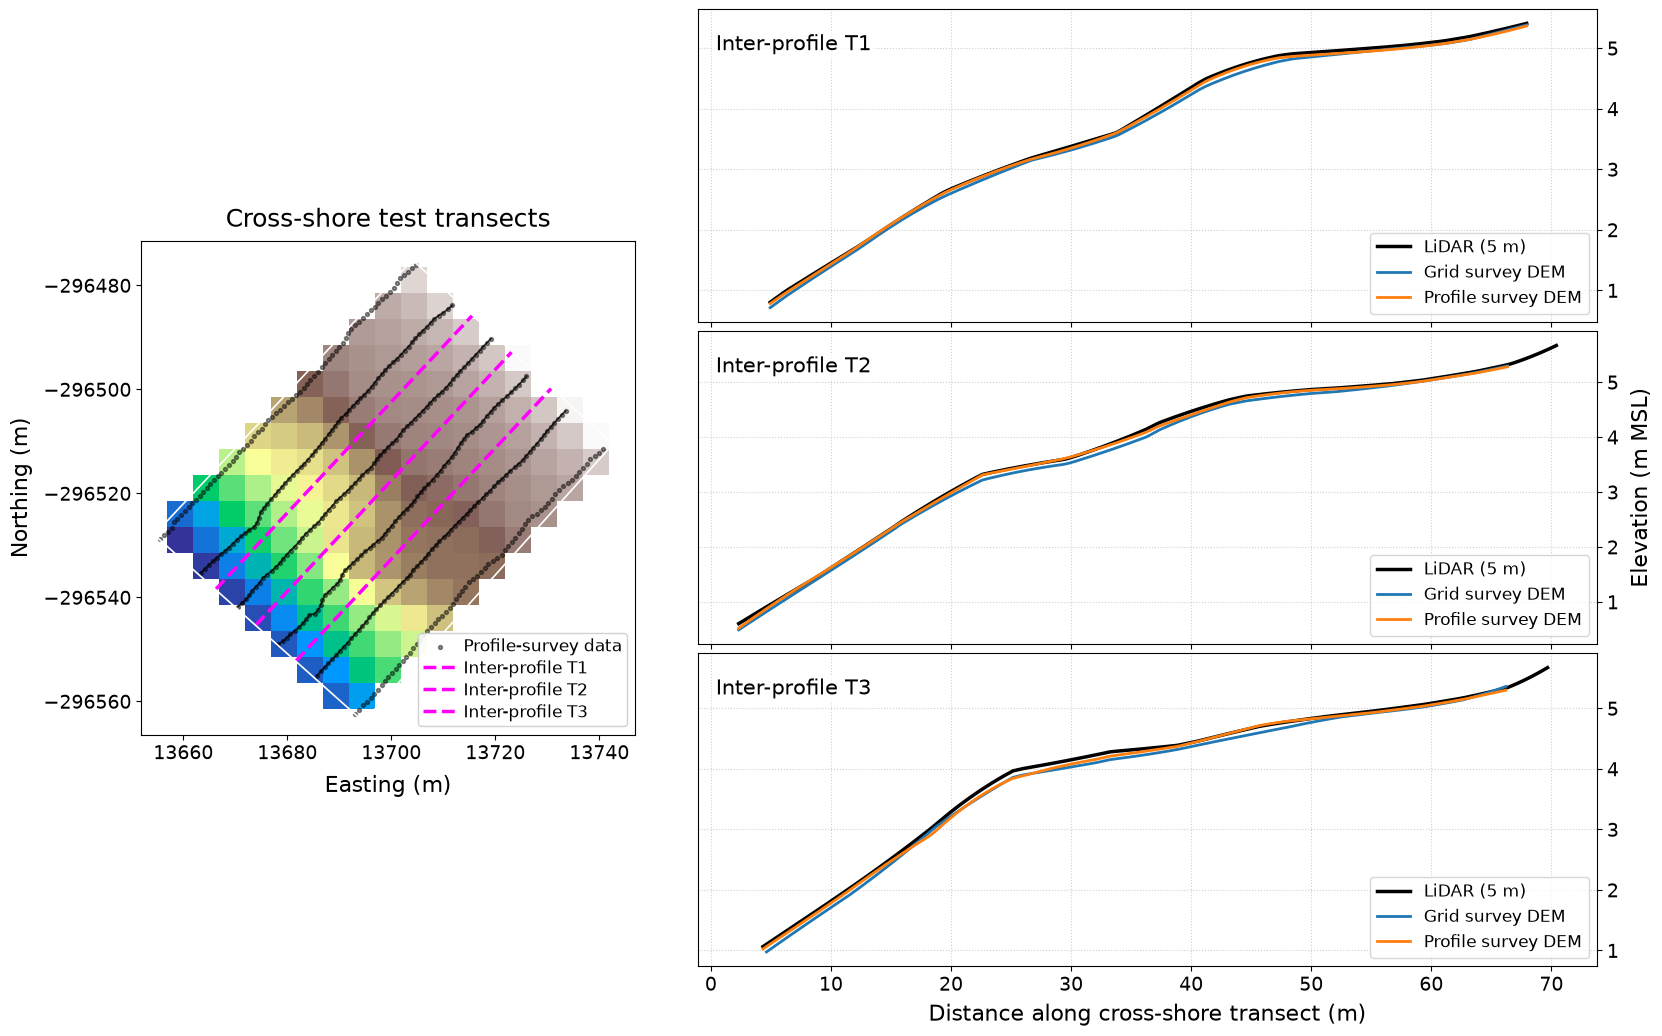

,transect,profile_n,profile_bias_m,profile_mae_m,profile_rmse_m,grid_n,grid_bias_m,grid_mae_m,grid_rmse_m
0,Inter-profile T1,218,-0.027,0.028,0.032,218,-0.064,0.064,0.069
1,Inter-profile T2,222,-0.021,0.023,0.029,222,-0.071,0.071,0.078
2,Inter-profile T3,215,-0.041,0.043,0.054,214,-0.079,0.080,0.086


In [13]:
# Visually compare surveys in combined figure:
# Left = Map of inter-profile transects
# Right = LiDAR / grid / profile comparisons along transects

n_samples = 250

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 12
})

fig = plt.figure(figsize=(16, 11), constrained_layout=False)

gs = GridSpec(
    3, 2,
    figure=fig,
    width_ratios=[0.78, 1.42],
    height_ratios=[1, 1, 1]
)

fig.subplots_adjust(
    left=0.07,
    right=0.98,
    bottom=0.08,
    top=0.95,
    wspace=0.09,
    hspace=0.03
)

# Left panel: Inter-profile transects map

ax_map = fig.add_subplot(gs[:, 0])

im = ax_map.pcolormesh(
    X, Y, lidar_5m,
    shading="auto",
    cmap="terrain"
)

ax_map.scatter(
    profiles_clean["easting"],
    profiles_clean["northing"],
    s=8,
    color="black",
    alpha=0.45,
    label="Profile-survey data"
)

for item in transects:
    x_line, y_line = item["line"].xy
    ax_map.plot(
        x_line, y_line,
        color="black",
        linewidth=1.3,
        alpha=0.75
    )

for item in interprofile_transects:
    x_line, y_line = item["line"].xy
    ax_map.plot(
        x_line, y_line,
        color="magenta",
        linestyle="--",
        linewidth=2.5,
        label=item["name"]
    )

ax_map.plot(polygon_x, polygon_y, color="white", linewidth=1.2)

ax_map.set_title("Cross-shore test transects", pad=10)
ax_map.set_xlabel("Easting (m)", labelpad=8)
ax_map.set_ylabel("Northing (m)", labelpad=8)
ax_map.set_aspect("equal")
ax_map.tick_params(axis="both", which="major", labelsize=14)

handles, labels = ax_map.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax_map.legend(
    by_label.values(),
    by_label.keys(),
    loc="best",
    frameon=True,
    facecolor="white",
    framealpha=0.9,
    borderpad=0.3,
    handletextpad=0.4,
    labelspacing=0.3
)


# Right panel: profiles along inter-profile transects

ax_p1 = fig.add_subplot(gs[0, 1])
ax_p2 = fig.add_subplot(gs[1, 1], sharex=ax_p1)
ax_p3 = fig.add_subplot(gs[2, 1], sharex=ax_p1)
axes_profiles = [ax_p1, ax_p2, ax_p3]

transect_metrics = []

for ax, item in zip(axes_profiles, interprofile_transects):

    line = item["line"]

    distance_m = np.linspace(0, line.length, n_samples)
    points = [line.interpolate(distance) for distance in distance_m]

    x_line = np.array([point.x for point in points])
    y_line = np.array([point.y for point in points])

    sample_yx = np.column_stack([y_line, x_line])

    z_grid = grid_sampler(sample_yx)
    z_profile = profile_sampler(sample_yx)
    z_lidar = lidar_sampler(sample_yx)

    valid_profile = np.isfinite(z_profile) & np.isfinite(z_lidar)
    valid_grid = np.isfinite(z_grid) & np.isfinite(z_lidar)

    profile_residual = z_profile[valid_profile] - z_lidar[valid_profile]
    grid_residual = z_grid[valid_grid] - z_lidar[valid_grid]

    transect_metrics.append({
        "transect": item["name"],
        "profile_n": valid_profile.sum(),
        "profile_bias_m": np.mean(profile_residual),
        "profile_mae_m": np.mean(np.abs(profile_residual)),
        "profile_rmse_m": np.sqrt(np.mean(profile_residual ** 2)),
        "grid_n": valid_grid.sum(),
        "grid_bias_m": np.mean(grid_residual),
        "grid_mae_m": np.mean(np.abs(grid_residual)),
        "grid_rmse_m": np.sqrt(np.mean(grid_residual ** 2))
    })

    ax.plot(
        distance_m,
        z_lidar,
        color="black",
        linewidth=2.5,
        label="LiDAR (5 m)"
    )
    ax.plot(
        distance_m,
        z_grid,
        color="tab:blue",
        linewidth=2,
        label="Grid survey DEM"
    )
    ax.plot(
        distance_m,
        z_profile,
        color="tab:orange",
        linewidth=2,
        label="Profile survey DEM"
    )

    ax.text(
        0.02, 0.92,
        f"{item['name']}",
        transform=ax.transAxes,
        fontsize=15,
        ha="left",
        va="top",
        bbox=dict(facecolor="white", alpha=0.75, edgecolor="none", pad=2.5)
    )

    ax.yaxis.tick_right()
    ax.yaxis.set_label_position("right")
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(loc="best")
    ax.tick_params(axis="both", which="major", labelsize=14)

for ax in axes_profiles[:-1]:
    ax.tick_params(labelbottom=False)

axes_profiles[-1].set_xlabel("Distance along cross-shore transect (m)", labelpad=6)

axes_profiles[0].set_ylabel("")
axes_profiles[1].set_ylabel("Elevation (m MSL)", labelpad=8)
axes_profiles[2].set_ylabel("")

fig.savefig(
    "interprofile_transects_comparison.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

interprofile_metrics = pd.DataFrame(transect_metrics)
display(interprofile_metrics.round(3))

In [14]:
## Qualitative assessment of DEMs
# Cell-by-cell statistics: DGNSS DEMs relative to LiDAR

common_valid = (
    inside_mask
    & np.isfinite(dem_grid_linear)
    & np.isfinite(dem_profiles_linear)
    & np.isfinite(lidar_5m)
)

def metrics_against_lidar(dem, lidar, valid_mask):
    dz = dem[valid_mask] - lidar[valid_mask]

    return {
        "n_5m_cells": dz.size,
        "bias_m": np.mean(dz),
        "median_bias_m": np.median(dz),
        "mae_m": np.mean(np.abs(dz)),
        "rmse_m": np.sqrt(np.mean(dz ** 2)),
        "std_residual_m": np.std(dz, ddof=1),
    }

stats_table = pd.DataFrame(
    [
        metrics_against_lidar(dem_grid_linear, lidar_5m, common_valid),
        metrics_against_lidar(dem_profiles_linear, lidar_5m, common_valid),
    ],
    index=[
        "Grid-survey DEM vs LiDAR",
        "Profile-survey DEM vs LiDAR"
    ]
)

display(stats_table.round(3))

,n_5m_cells,bias_m,median_bias_m,mae_m,rmse_m,std_residual_m
Grid-survey DEM vs LiDAR,141,-0.075,-0.075,0.076,0.089,0.048
Profile-survey DEM vs LiDAR,141,-0.031,-0.026,0.034,0.048,0.037


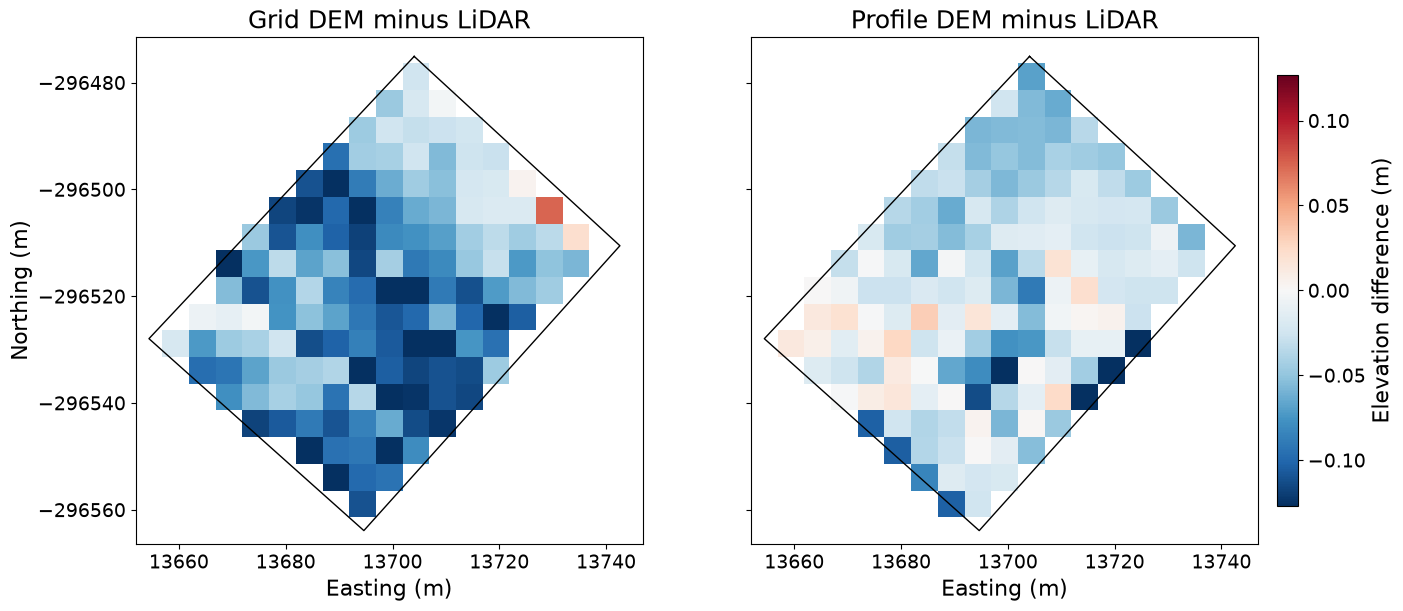

In [15]:
# Residual maps: positive = DGNSS DEM higher than LiDAR

res_grid = dem_grid_linear - lidar_5m
res_profile = dem_profiles_linear - lidar_5m

limit = np.percentile(
    np.abs(np.concatenate([
        res_grid[common_valid],
        res_profile[common_valid]
    ])),
    95
)

fig, axes = plt.subplots(
    1, 2, figsize=(14, 6),
    sharex=True, sharey=True, constrained_layout=True
)

for ax, residual, title in zip(
    axes,
    [res_grid, res_profile],
    ["Grid DEM minus LiDAR", "Profile DEM minus LiDAR"]
):
    im = ax.pcolormesh(
        X, Y, residual, shading="auto",
        cmap="RdBu_r", vmin=-limit, vmax=limit
    )
    ax.plot(polygon_x, polygon_y, color="black", linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("Easting (m)")
    ax.set_aspect("equal")

axes[0].set_ylabel("Northing (m)")
fig.colorbar(im, ax=axes, shrink=0.85, pad=0.015, label="Elevation difference (m)")
fig.savefig(
    "dem_residual_maps.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [16]:
# Qualitative assessment, using 0.05 grid
# These DGNSS DEMs are interpolated display products only.

# Native clipped LiDAR surface
lidar_native = np.asarray(lidar_z, dtype=float)

# Convert any LiDAR NoData values to NaN
lidar_native[lidar_native <= -9990] = np.nan

# Native LiDAR coordinate grids from its affine transform
n_rows, n_cols = lidar_native.shape

col_index = np.arange(n_cols)
row_index = np.arange(n_rows)

cols, rows = np.meshgrid(col_index, row_index)

X_native = (
    lidar_transform.c
    + (cols + 0.5) * lidar_transform.a
    + (rows + 0.5) * lidar_transform.b
)

Y_native = (
    lidar_transform.f
    + (cols + 0.5) * lidar_transform.d
    + (rows + 0.5) * lidar_transform.e
)

# Apply exactly the same AOI polygon to the LiDAR grid
native_points = shapely.points(X_native.ravel(), Y_native.ravel())

inside_native = shapely.covers(
    area_polygon,
    native_points
).reshape(X_native.shape)

lidar_native[~inside_native] = np.nan

# Grid-survey DEM, interpolated onto 0.05 m LiDAR cells
dem_grid_native = griddata(
    points=grid_clean[["easting", "northing"]].to_numpy(),
    values=grid_clean["elevation"].to_numpy(),
    xi=(X_native, Y_native),
    method="linear",
    fill_value=np.nan
)

dem_grid_native[~inside_native] = np.nan

# Profile-survey DEM, interpolated onto 0.05 m LiDAR cells
dem_profile_native = griddata(
    points=profiles_clean[["easting", "northing"]].to_numpy(),
    values=profiles_clean["elevation"].to_numpy(),
    xi=(X_native, Y_native),
    method="linear",
    fill_value=np.nan
)

dem_profile_native[~inside_native] = np.nan

print("Native LiDAR grid shape:", X_native.shape)
print("Native cell size:", abs(lidar_transform.a), "m")

Native LiDAR grid shape: (1777, 1765)
Native cell size: 0.05 m


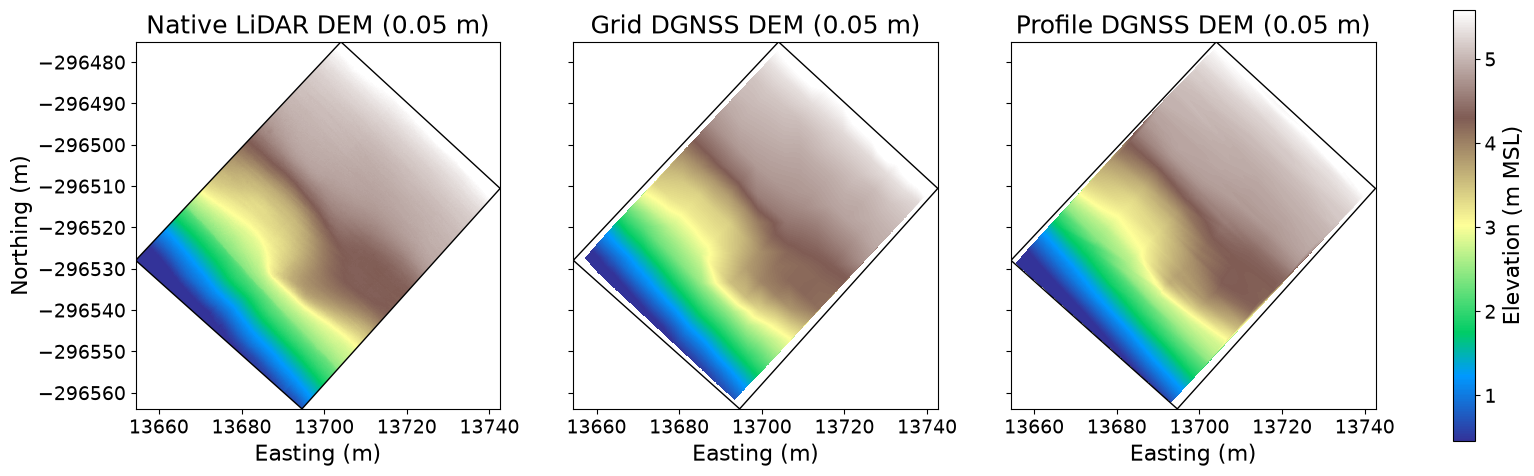

In [17]:
# Side-by-side elevation comparison at 0.05 m display scale
valid_elevation = np.concatenate([
    lidar_native[np.isfinite(lidar_native)],
    dem_grid_native[np.isfinite(dem_grid_native)],
    dem_profile_native[np.isfinite(dem_profile_native)]
])

vmin, vmax = np.percentile(valid_elevation, [2, 98])

fig, axes = plt.subplots(
    1, 3,
    figsize=(20, 7),
    sharex=True,
    sharey=True,
    constrained_layout=False
)

products = [
    (lidar_native, "Native LiDAR DEM (0.05 m)"),
    (dem_grid_native, "Grid DGNSS DEM (0.05 m)"),
    (dem_profile_native, "Profile DGNSS DEM (0.05 m)")
]

for ax, (dem, title) in zip(axes, products):
    im = ax.pcolormesh(
        X_native,
        Y_native,
        dem,
        shading="auto",
        cmap="terrain",
        vmin=vmin,
        vmax=vmax
    )

    ax.plot(polygon_x, polygon_y, color="black", linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("Easting (m)")
    ax.set_aspect("equal")

axes[0].set_ylabel("Northing (m)")

fig.colorbar(
    im,
    ax=axes,
    shrink=0.80,
    label="Elevation (m MSL)"
)

plt.show()

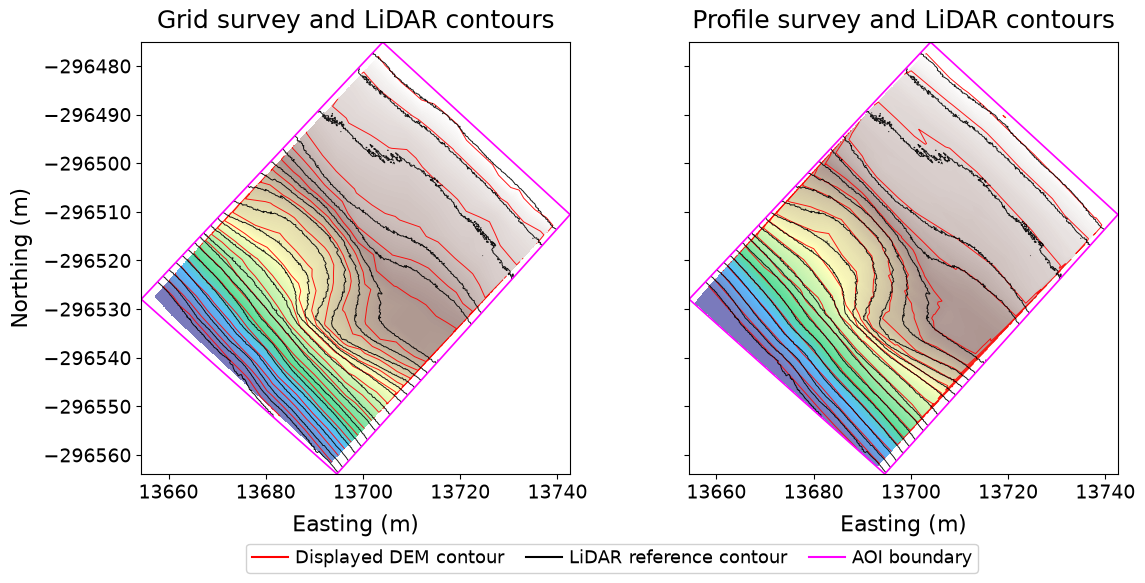

In [18]:
# Qualitative morphology: DGNSS contours against LiDAR contours

contour_interval = 0.25  # m

all_elevations = np.concatenate([
    lidar_native[np.isfinite(lidar_native)],
    dem_grid_native[np.isfinite(dem_grid_native)],
    dem_profile_native[np.isfinite(dem_profile_native)]
])

z_min = np.ceil(np.nanpercentile(all_elevations, 2) / contour_interval) * contour_interval
z_max = np.floor(np.nanpercentile(all_elevations, 98) / contour_interval) * contour_interval
levels = np.arange(z_min, z_max + contour_interval, contour_interval)

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 13
})

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6),
    sharex=True,
    sharey=True,
    constrained_layout=False
)

fig.subplots_adjust(
    wspace=0.02,
    bottom=0.16
)

products = [
    (dem_grid_native, "Grid survey and LiDAR contours"),
    (dem_profile_native, "Profile survey and LiDAR contours")
]

for ax, (dem, title) in zip(axes, products):
    ax.pcolormesh(
        X_native,
        Y_native,
        dem,
        shading="auto",
        cmap="terrain",
        alpha=0.65,
        vmin=z_min,
        vmax=z_max
    )

    ax.contour(
        X_native,
        Y_native,
        dem,
        levels=levels,
        colors="red",
        linewidths=0.7,
        alpha=0.9
    )

    ax.contour(
        X_native,
        Y_native,
        lidar_native,
        levels=levels,
        colors="black",
        linewidths=0.7,
        alpha=0.9
    )

    ax.plot(polygon_x, polygon_y, color="magenta", linewidth=1.2)
    ax.set_title(title, pad=10)
    ax.set_xlabel("Easting (m)", labelpad=8)
    ax.set_aspect("equal")
    ax.tick_params(axis="both", which="major", labelsize=14)

axes[0].set_ylabel("Northing (m)", labelpad=8)

handles = [
    Line2D([0], [0], color="red", lw=1.5, label="Displayed DEM contour"),
    Line2D([0], [0], color="black", lw=1.5, label="LiDAR reference contour"),
    Line2D([0], [0], color="magenta", lw=1.5, label="AOI boundary")
]

fig.legend(
    handles=handles,
    loc="lower center",
    ncol=3,
    frameon=True,
    facecolor="white",
    framealpha=0.9,
    bbox_to_anchor=(0.5, -0.02),
    borderpad=0.3,
    handletextpad=0.4,
    columnspacing=1.2
)

fig.savefig(
    "contours_dgnss_vs_lidar.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()